# 01 — Data Exploration (EDA)
## AI101 Mini Project: Mobile Phone Price Range Classification

**Team member:** Member 1 Ashish Kumar — Dataset & EDA  
**Objective:** Understand the dataset, verify the target variable, inspect data quality, study class balance, and identify potentially informative features before preprocessing and modelling.

The target column is `price_range`:
- `0` = Low cost
- `1` = Medium cost
- `2` = High cost
- `3` = Very high cost

This notebook performs exploration only. It does **not** fit a machine-learning model or make feature-selection decisions.

In [11]:
# 1. Import libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Load the dataset



In [12]:

df = pd.read_csv("../data/Data.csv")
print("Loaded:", "../data/Data.csv")
print("Dataset shape:", df.shape)
display(df.head())

Loaded: ../data/Data.csv
Dataset shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.200,0,1,0,7.000,0.600,188,2,2,20,756.000,"2,549.000",9,7,19,0.000,0,1,1
1,1021,1,0.500,1,0,1,53.000,0.700,136,3,6,905,"1,988.000","2,631.000",17,3,7,1.000,1,0,2
2,563,1,0.500,1,2,1,41.000,0.900,145,5,6,1263,"1,716.000","2,603.000",11,2,9,1.000,1,0,2
3,615,1,2.500,0,0,0,10.000,0.800,131,6,9,1216,"1,786.000","2,769.000",16,8,11,1.000,0,0,2
4,1821,1,1.200,0,13,1,44.000,0.600,141,2,14,1208,"1,212.000","1,411.000",8,2,15,1.000,1,0,1


## 3. Understand rows, columns and data types

The expected dataset has 2,000 records, 20 predictor columns and one target column (`price_range`). Verify this from the loaded file rather than assuming it.

In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nDataFrame information:")
df.info()

display(df.describe().T)

Rows: 2000
Columns: 21
\nColumn names:
['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'price_range']
\nDataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     1999 non-null   float64
 7   m_dep          1999 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null  

,count,mean,std,min,25%,50%,75%,max
battery_power,"2,000.000","1,238.518",439.418,501.000,851.750,"1,226.000","1,615.250","1,998.000"
blue,"2,000.000",0.495,0.500,0.000,0.000,0.000,1.000,1.000
clock_speed,"2,000.000",1.522,0.816,0.500,0.700,1.500,2.200,3.000
dual_sim,"2,000.000",0.509,0.500,0.000,0.000,1.000,1.000,1.000
fc,"2,000.000",4.309,4.341,0.000,1.000,3.000,7.000,19.000
four_g,"2,000.000",0.521,0.500,0.000,0.000,1.000,1.000,1.000
int_memory,"1,999.000",32.035,18.143,2.000,16.000,32.000,48.000,64.000
m_dep,"1,999.000",0.502,0.288,0.100,0.200,0.500,0.800,1.000
mobile_wt,"2,000.000",140.249,35.400,80.000,109.000,141.000,170.000,200.000
n_cores,"2,000.000",4.521,2.288,1.000,3.000,4.000,7.000,8.000


## 4. Check missing values and duplicate rows

Missing values must be handled in the preprocessing stage.

In [15]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

print("Missing values by column:")
display(missing.to_frame("missing_count"))

print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Missing values by column:


,missing_count
three_g,1
ram,1
px_width,1
m_dep,1
int_memory,1


Total missing cells: 5
Duplicate rows: 0


## 5. Inspect target distribution

A balanced target means each class has a similar number of observations. This helps us decide whether class weighting or resampling is necessary. The target should be kept as a four-class categorical outcome.

,class_label,count,percentage
0,Low cost,500,25.000
1,Medium cost,500,25.000
2,High cost,500,25.000
3,Very high cost,500,25.000


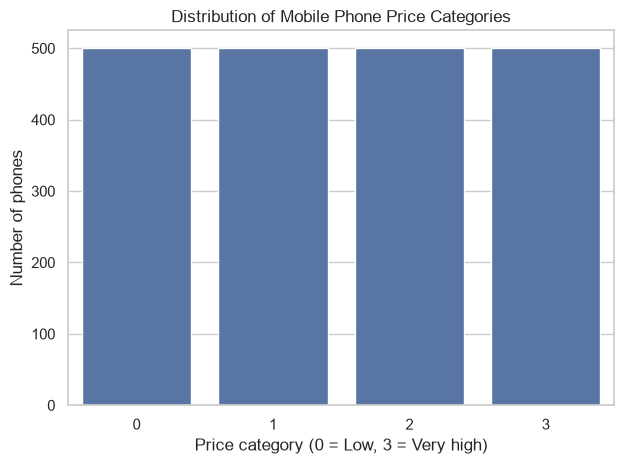

In [8]:
target_labels = {
    0: "Low cost",
    1: "Medium cost",
    2: "High cost",
    3: "Very high cost",
}

target_counts = df["price_range"].value_counts().sort_index()
target_table = pd.DataFrame({
    "class_label": [target_labels.get(i, str(i)) for i in target_counts.index],
    "count": target_counts.values,
    "percentage": (target_counts.values / len(df) * 100).round(2),
})
display(target_table)

ax = sns.countplot(data=df, x="price_range", order=[0, 1, 2, 3])
ax.set_title("Distribution of Mobile Phone Price Categories")
ax.set_xlabel("Price category (0 = Low, 3 = Very high)")
ax.set_ylabel("Number of phones")
plt.tight_layout()
plt.show()

## 6. Compare important numerical features across price categories



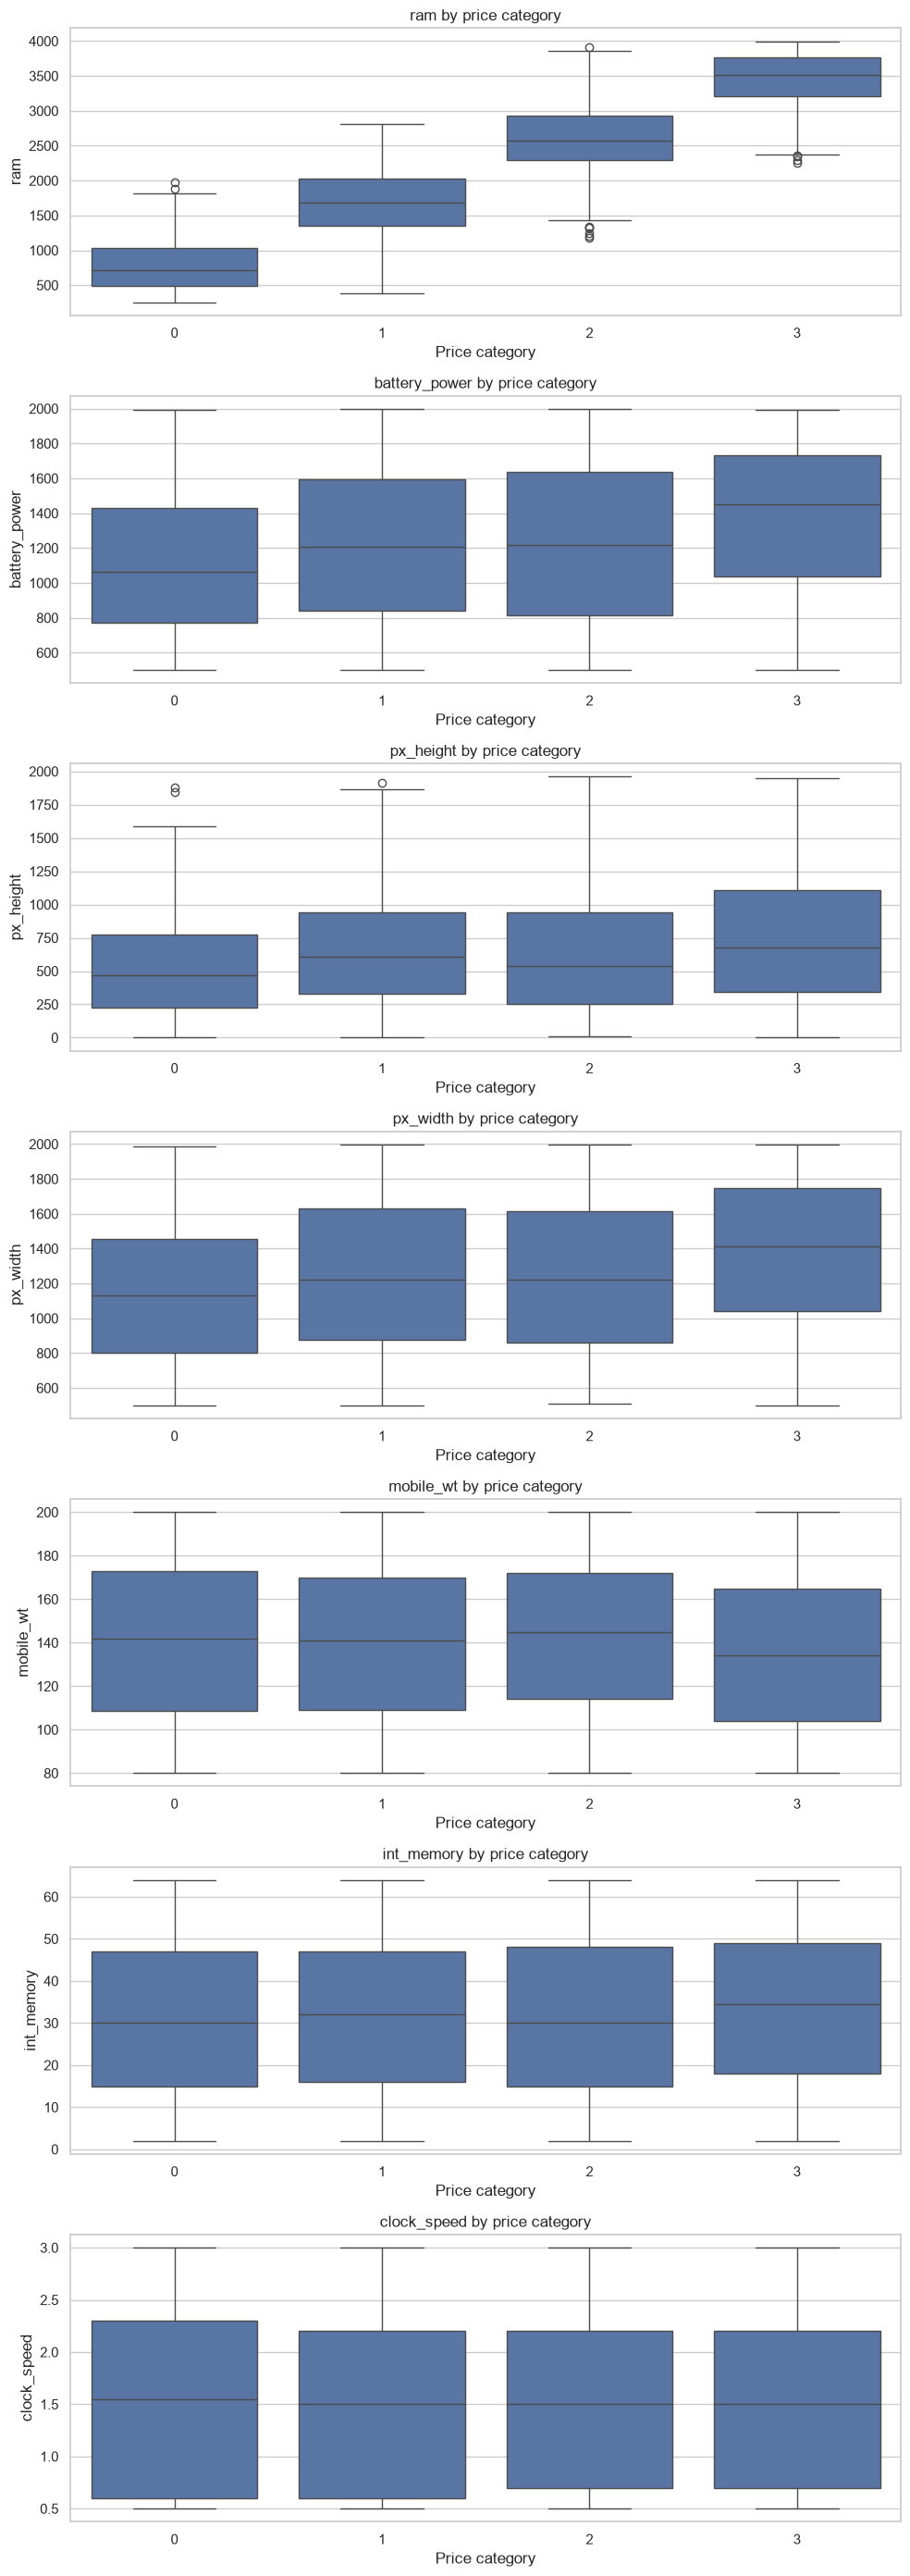

In [16]:
candidate_features = [
    "ram", "battery_power", "px_height", "px_width",
    "mobile_wt", "int_memory", "clock_speed"
]
available_features = [c for c in candidate_features if c in df.columns]

fig, axes = plt.subplots(len(available_features), 1, figsize=(10, 4 * len(available_features)))
if len(available_features) == 1:
    axes = [axes]

for ax, feature in zip(axes, available_features):
    sns.boxplot(data=df, x="price_range", y=feature, order=[0, 1, 2, 3], ax=ax)
    ax.set_title(f"{feature} by price category")
    ax.set_xlabel("Price category")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

## 7. Correlation analysis


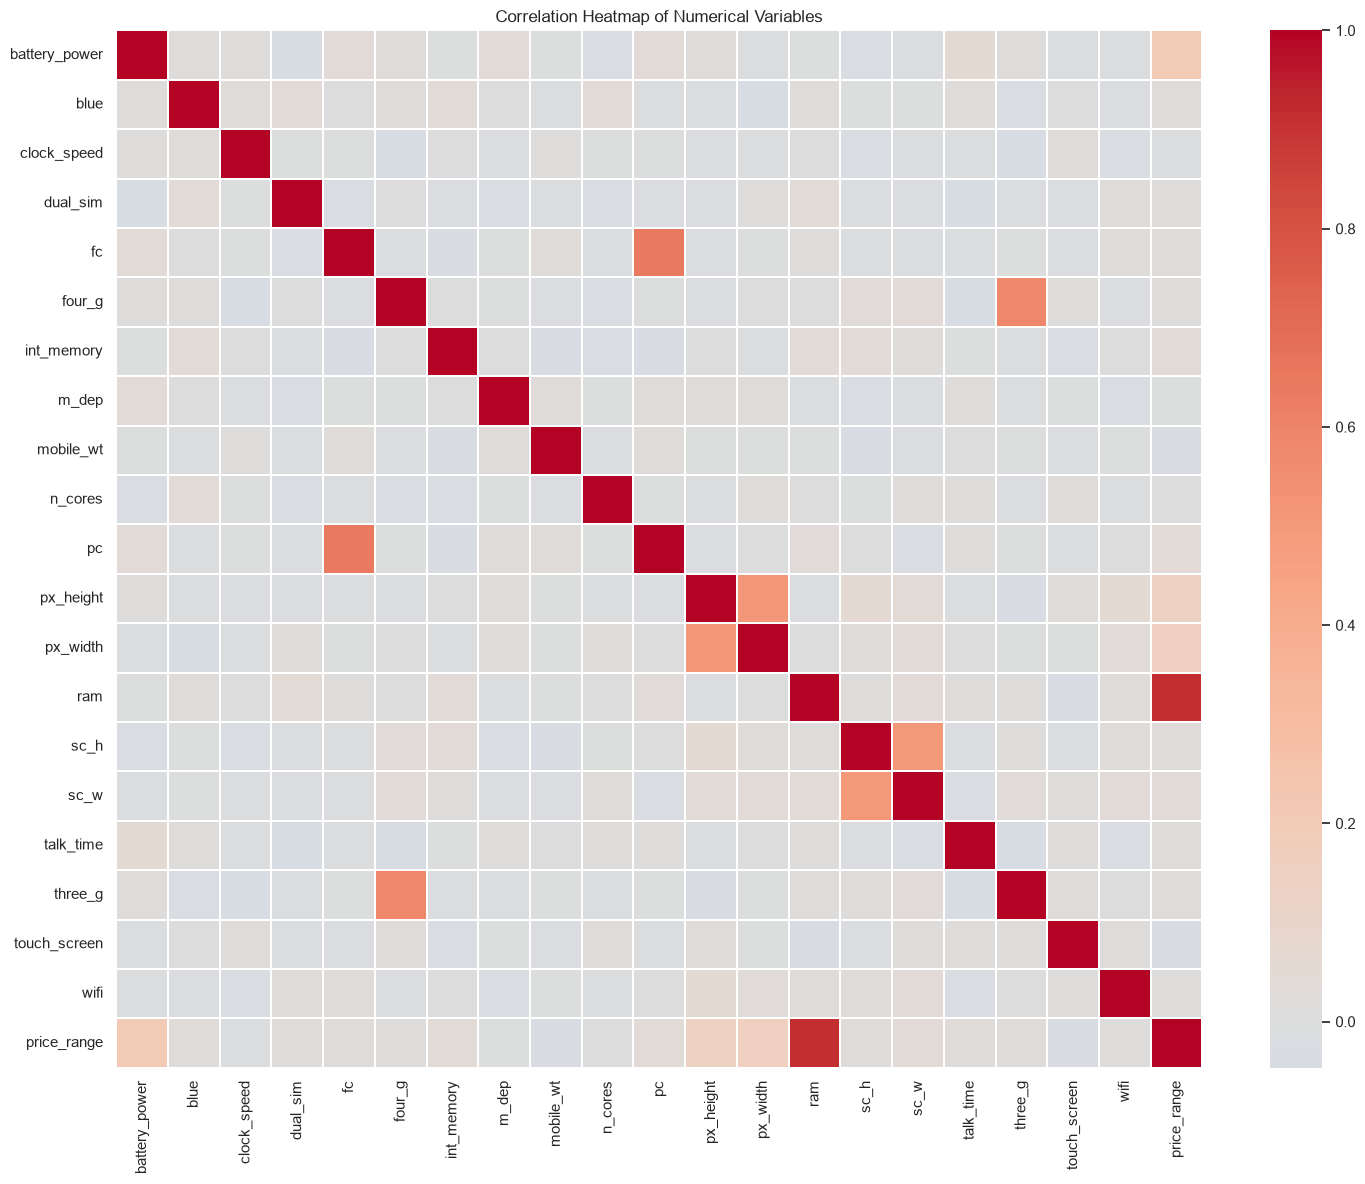

,correlation_with_price_range
ram,0.917
battery_power,0.201
px_width,0.166
px_height,0.149
int_memory,0.044
sc_w,0.039
pc,0.034
touch_screen,-0.030
mobile_wt,-0.030
three_g,0.024


In [17]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.2)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

target_corr = corr["price_range"].drop("price_range").sort_values(
    key=lambda s: s.abs(), ascending=False
)
display(target_corr.to_frame("correlation_with_price_range"))

## 8. EDA findings

Record findings from the actual outputs above. For the supplied dataset, the initial inspection found:

- 2,000 rows and 21 columns.
- `price_range` is present and contains four classes (0, 1, 2, 3).
- The four target classes each contain 500 records (25% each).
- Five missing cells are present: one each in `int_memory`, `m_dep`, `px_width`, `ram`, and `three_g`.
- No duplicate rows were found.
- `ram` has the strongest positive Pearson correlation with `price_range` in this dataset; `battery_power`, `px_width`, and `px_height` also show positive associations. This is exploratory evidence only, not the final feature selection.

